# Hybrid RAG System with Automated Evaluation

Objective
Build a Hybrid Retrieval-Augmented Generation (RAG) system combining dense vector retrieval, sparse keyword retrieval (BM25), and Reciprocal Rank Fusion (RRF) to answer questions from 500 Wikipedia articles. Evaluate using an automated framework with 100 generated questions.

In [1]:
!pip install wikipedia-api
!pip install langchain-text-splitters

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.7/44.7 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.8/129.8 kB 6.9 MB/s eta 0:00:00


In [2]:
import wikipediaapi
import random
import json
import uuid
import time
import numpy as np
from langchain_text_splitters import RecursiveCharacterTextSplitter
import os
from tqdm.auto import tqdm
import pandas as pd
from transformers import AutoTokenizer
import requests
import torch
import warnings
warnings.filterwarnings('ignore')


### Dataset Requirements
Wikipedia URL Collection (500 URLs per group):

Fixed Set (200 URLs): Each group must first sample a unique set of 200 Wikipedia URLs (minimum 200 words per page) covering diverse topics. Store these in a JSON file (fixed_urls.json). No two groups should share the same 200 URLs. These URLs remain constant across all indexing operations.

Random Set (300 URLs): For each indexing run, randomly sample 300 additional Wikipedia URLs (minimum 200 words per page). These should change every time the system is rebuilt/indexed.

Total Corpus: 200 fixed + 300 random = 500 URLs. Extract, clean, and chunk the text (200-400 tokens with 50-token overlap). Store with metadata (URL, title, unique chunk IDs).

In [7]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

core_topics = [
            # Science
            "Artificial_intelligence", "Quantum_mechanics", "Genetics", "Climate_change",
            "Big_Bang", "Evolution", "Neuroscience", "Renewable_energy",
            "Nanotechnology", "Bioinformatics", "Ecology", "Astrophysics",

            # Technology
            "Machine_learning", "Blockchain", "Internet", "Computer_science",
            "Robotics", "Cybersecurity", "Data_science", "3D_printing",

            # History
            "World_War_II", "Renaissance", "Ancient_Rome", "French_Revolution",
            "Industrial_Revolution", "Cold_War", "Middle_Ages", "Age_of_Enlightenment",

            # Arts & Humanities
            "Renaissance_art", "Classical_music", "Modern_literature", "Philosophy",
            "Architecture", "Cinema", "Theatre", "Photography",

            # Social Sciences
            "Psychology", "Economics", "Sociology", "Political_science",
            "Anthropology", "Linguistics", "Education", "International_relations",

            # Health & Medicine
            "Immunology", "Nutrition", "Mental_health", "Public_health",
            "Pharmacology", "Surgery", "Epidemiology", "Genomics",

            # Geography & Environment
            "Geography", "Oceanography", "Geology", "Meteorology",
            "Sustainability", "Conservation_biology", "Agriculture", "Urban_planning",

            # Mathematics
            "Mathematics", "Statistics", "Calculus", "Number_theory",
            "Geometry", "Algebra", "Probability", "Cryptography",

            # Business & Economics
            "Economics", "Finance", "Marketing", "Entrepreneurship",
            "Management", "Accounting", "Microeconomics", "Macroeconomics"
        ]

#### URLs Generator
* Collect urls from core topics
* Get 200 fixed url set from core topics
* Get random 300 urls
* Store both fixed urls and random urls to all_urls.json file

In [16]:
# from google.colab import drive
# drive.mount('/content/drive')
os.mkdir("Data")
corpus_data_file = "Data/corpus_data.json"
fixed_urls_file = "Data/fixed_urls.json"
all_urls_path = "Data/all_urls.json"

In [17]:
NUM_FIXED_URLS = 200
NUM_RANDOM_URLS = 300

wiki = wikipediaapi.Wikipedia(
    user_agent="Wiki-url-fetcher/2.0",
    language='en',
    extract_format=wikipediaapi.ExtractFormat.WIKI
)

def get_valid_wiki_pages(count, urls):
    MAX_RETRIES = 3
    INITIAL_RETRY_DELAY = 1 # seconds

    with tqdm(total=count, initial=len(urls), desc="Fetching Wikipedia URLs") as pbar:
        while len(urls) < count:
            cat_name = random.choice(core_topics)
            cat = wiki.page(f"Category:{cat_name}")

            members = []
            for attempt_cat in range(MAX_RETRIES):
                try:
                    members = list(cat.categorymembers.values())
                    if members:
                        break # Successfully fetched members
                    else:
                        break # Category is genuinely empty
                except (json.JSONDecodeError, requests.exceptions.RequestException) as e:
                    if attempt_cat < MAX_RETRIES - 1:
                        retry_delay = INITIAL_RETRY_DELAY * (2 ** attempt_cat)
                        print(f"Retrying category '{cat_name}' due to API error: {e}. Attempt {attempt_cat + 1}/{MAX_RETRIES}. Retrying in {retry_delay}s...")
                        time.sleep(retry_delay)
                    else:
                        print(f"Failed to fetch category '{cat_name}' after {MAX_RETRIES} attempts due to: {e}")
                        break # Give up on this category
                except Exception as e:
                    print(f"Skipping category '{cat_name}' due to unexpected error: {e}")
                    break

            if not members: # If no members were fetched or retry failed, continue to next topic
                continue

            page = random.choice(members)
            page_title = page.title # Store title for robust logging
            page_fullurl = page.fullurl # Store fullurl for robust logging

            for attempt_page in range(MAX_RETRIES):
                try:
                    if page.ns == wikipediaapi.Namespace.MAIN and page.exists() and len(page.text.split()) >= 200:
                        if page_fullurl not in urls:
                            urls.append(page_fullurl)
                            pbar.update(1)
                            time.sleep(0.1) # delay to avoid hitting API limits
                        break # Successfully processed, break from retry loop
                    elif not page.exists():
                        print(f"Skipping page '{page_title}' ({page_fullurl}) as it does not exist.")
                        break # Page legitimately doesn't exist, no need to retry
                    else:
                        break # No need to retry if criteria not met

                except (json.JSONDecodeError, requests.exceptions.RequestException) as e:
                    if attempt_page < MAX_RETRIES - 1:
                        retry_delay = INITIAL_RETRY_DELAY * (2 ** attempt_page) # Exponential backoff
                        print(f"Retrying page '{page_title}' ({page_fullurl}) due to API error: {e}. Attempt {attempt_page + 1}/{MAX_RETRIES}. Retrying in {retry_delay}s...")
                        time.sleep(retry_delay)
                    else:
                        print(f"Failed to process page '{page_title}' ({page_fullurl}) after {MAX_RETRIES} attempts due to: {e}")
                except Exception as e:
                    print(f"Skipping page '{page_title}' ({page_fullurl}) due to unexpected error: {e}")
                    break # For other unexpected errors, don't retry
    return urls

# --- Fixed Set (Run once) ---
print("\nGetting fixed urls...")
fixed_urls = []
if os.path.exists(fixed_urls_file):
    with open(fixed_urls_file, 'r') as f:
        fixed_urls = json.load(f)
    print(f"Loaded {len(fixed_urls)} fixed URLs from file {fixed_urls_file}")
else:
    fixed_urls = get_valid_wiki_pages(NUM_FIXED_URLS, fixed_urls)
    with open(fixed_urls_file, 'w') as f:
        json.dump(fixed_urls, f)
    print(f"Fetched and saved {len(fixed_urls)} fixed URLs to {fixed_urls_file}")

all_urls = fixed_urls

# --- Random Set ( Run Everytime )---
print("\nGetting random urls...")
get_valid_wiki_pages(NUM_RANDOM_URLS+NUM_FIXED_URLS, all_urls)

# Store the all_urls.json in temp storage
with open(all_urls_path, 'w') as f:
  json.dump(all_urls, f)
  print(f"Saved {len(all_urls)} URLs to all_urls.json")

print(f"Loaded Total {len(all_urls)} URLs")


Getting fixed urls...


Fetching Wikipedia URLs:   0%|          | 0/200 [00:00<?, ?it/s]

Fetched and saved 200 fixed URLs to Data/fixed_urls.json

Getting random urls...


Fetching Wikipedia URLs:  40%|####      | 200/500 [00:00<?, ?it/s]

Saved 500 URLs to all_urls.json
Loaded Total 500 URLs


In [19]:
# Test function to load all the urls from file
all_urls = []
if os.path.exists(all_urls_path):
    with open(all_urls_path, 'r') as f:
        all_urls = json.load(f)
    print(f"Loaded {len(all_urls)} all URLs ")
else:
    print(f"Error file not found")

Loaded 500 all URLs 


#### Wiki Corpus data generator

Clean the data retrieved from wikipedia pages

In [20]:
import re

def clean_text(text):
    """
    Cleans raw text by removing Wikipedia citations, normalizing whitespace,
    removing specific Wikipedia markup, and filtering out non-printable characters.
    """
    # 1. Remove large structural elements first (HTML tags, templates, tables, code, formulas)
    # Combine HTML tags, Wikipedia templates, table markup, code sections, and formulas into one step
    text = re.sub(r'<[^>]+>|\{\{[^\}]*\}\}|\{\|.*?\|\}|<syntaxhighlight>.*?</syntaxhighlight>|<code>.*?</code>|<math>.*?</math>', '', text, flags=re.DOTALL)

    # 2. Remove Wikipedia citations (e.g., [1], [23]) and '[edit]' markers
    text = re.sub(r'\[\d+\]|\[edit\]', '', text)

    # 3. Handle Wikipedia internal links
    # Convert [[Target Page|Display Text]] to Display Text
    text = re.sub(r'\[\[[^\]|]+\|([^\]]+)\]\]', r'\1', text)
    # Convert [[Target Page]] to Target Page
    text = re.sub(r'\[\[([^\]]+)\]\]', r'\1', text)

    # 4. Handle Wikipedia external links
    # Convert [http://example.com Link text] to Link text
    text = re.sub(r'\[https?:\/\/[^\s]+ ([^\]]+)\]', r'\1', text)
    # Remove [http://example.com] entirely
    text = re.sub(r'\[https?:\/\/[^\]]+\]', '', text)

    # 5. Remove bold/italic formatting ('''text''' or ''text'')
    text = re.sub(r"'{2,5}", '', text)

    # 6. Remove common non-content Wikipedia section headers
    # These patterns target lines that are solely section headers like "== See also =="
    non_content_headers = [
        "See also", "References", "External links", "Further reading",
        "Notes", "Citations", "Bibliography", "Links", "Footnotes", "Sources"
    ]
    header_pattern = r'^=+\s*(?:' + '|'.join(re.escape(h) for h in non_content_headers) + r')\s*=+\s*$' # Use re.escape for special chars in headers
    text = re.sub(header_pattern, '', text, flags=re.IGNORECASE | re.MULTILINE)

    # 7. Normalize whitespace: replace any sequence of whitespace (newlines, tabs, etc.) with a single space
    text = re.sub(r'\s+', ' ', text)

    # 8. Remove non-printable characters (keep only printable ASCII characters from space to ~)
    # This maintains the original intent of the provided code.
    text = ''.join(c for c in text if 31 < ord(c) < 127 or c == ' ')

    # 9. Strip leading/trailing whitespace
    return text.strip()

* Retrieve the wiki page data using Wiki API by loading all_urls.json file

* Create text chunks and store the corpus data in json format


In [21]:
CHUNK_SIZE = 400
CHUNK_OVERLAP = 50
from google.colab import userdata
hf_token = userdata.get('HF_TOKEN') or os.getenv('HF_TOKEN')
# Initialize tokenizer for token-based splitting
# Using the same model and token defined in the generation section
tokenizer = AutoTokenizer.from_pretrained("meta-llama/Llama-2-7b-chat-hf",token=hf_token)

wiki = wikipediaapi.Wikipedia(
    user_agent="RAG-Page-Fetcher/2.0",
    language='en',
    extract_format=wikipediaapi.ExtractFormat.WIKI
)

def process_corpus(urls):
    corpus_chunks = []
    # Use the tokenizer for length calculation to ensure units are tokens
    text_splitter = RecursiveCharacterTextSplitter(
        chunk_size=CHUNK_SIZE,
        chunk_overlap=CHUNK_OVERLAP,
        length_function=lambda text: len(tokenizer.encode(text, add_special_tokens=False)),
        separators=["\n\n", "\n", ".", "!", "?", ",", " ", ""]
    )

    MAX_RETRIES = 3
    INITIAL_RETRY_DELAY = 1 # seconds

    for url in tqdm(urls, desc="Processing corpus chunks"):
        page_name = url.split('/')[-1]
        for attempt in range(MAX_RETRIES):
            try:
                page = wiki.page(page_name)
                if not page.exists():
                    print("page doesn't exist",page_name)
                    break # Page legitimately doesn't exist, no need to retry

                # Clean the page text before chunking
                cleaned_text = clean_text(page.text)
                chunks = text_splitter.split_text(cleaned_text)

                for chunk in chunks:
                    corpus_chunks.append({
                        "chunk_id": str(uuid.uuid4()),
                        "chunk_text": chunk,
                        "chunk_url": url,
                        "chunk_title": page.title
                    })
                time.sleep(INITIAL_RETRY_DELAY*0.1)
                break # Successfully processed, break from retry loop

            except (requests.exceptions.RequestException, json.JSONDecodeError) as e:
                if attempt < MAX_RETRIES - 1:
                    retry_delay = INITIAL_RETRY_DELAY * (2 ** attempt) # Exponential backoff
                    print(f"Retrying page '{page_name}' ({url}) due to error: {e}. Attempt {attempt + 1}/{MAX_RETRIES}. Retrying in {retry_delay}s...")
                    time.sleep(retry_delay)
                else:
                    print(f"Failed to process page '{page_name}' ({url}) after {MAX_RETRIES} attempts due to: {e}")
            except Exception as e:
                print(f"Skipping page '{page_name}' ({url}) due to unexpected error: {e}")
                break # For other unexpected errors, don't retry
    return corpus_chunks


# Get the corpus data from all_urls.json
corpus_data = process_corpus(all_urls)
print(f"\nCreated {len(corpus_data)} total chunks.")

# Store the corpus data to file
print(f"Saving corpus data to {corpus_data_file}...")
with open(corpus_data_file, 'w') as f:
    json.dump(corpus_data, f)
print("Corpus data saved.")

config.json:   0%|          | 0.00/614 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.62k [00:00<?, ?B/s]

tokenizer.model: reconstructing file:   0%|          |  0.00B /  500kB            

tokenizer.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/1.84M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/414 [00:00<?, ?B/s]

Processing corpus chunks:   0%|          | 0/500 [00:00<?, ?it/s]

page doesn't exist De_Vaucouleurs%27s_law
page doesn't exist Rank%E2%80%93size_distribution
page doesn't exist J_%26_E_Wood
page doesn't exist Abel%27s_summation_formula
page doesn't exist White%27s_law
page doesn't exist Jeans%27s_theorem
page doesn't exist Weil%E2%80%93Ch%C3%A2telet_group
page doesn't exist Amity%E2%80%93enmity_complex
page doesn't exist China%E2%80%93Cornell%E2%80%93Oxford_Project
page doesn't exist The_Machine_in_Neptune%27s_Garden
page doesn't exist Euler%27s_totient_function
page doesn't exist Honor%C3%A9-Nicolas-Marie_Duveyrier
page doesn't exist Charles-Fran%C3%A7ois_Richard
page doesn't exist Fran%C3%A7ois_Augustin_Roussel
page doesn't exist Institut_f%C3%BCr_Meereskunde_Kiel
page doesn't exist Professional%E2%80%93managerial_class
page doesn't exist Reflections_in_Bullough%27s_Pond
page doesn't exist Str%C3%A4hle_construction
page doesn't exist George_Saxon_%26_Co

Created 4418 total chunks.
Saving corpus data to Data/corpus_data.json...
Corpus data saved.


In [23]:
# Install rag dependencies
!pip install faiss-cpu rank_bm25
!pip install sentence-transformers transformers
!pip install torch accelerate bitsandbytes nltk rouge-score bert-score scikit-learn matplotlib seaborn pandas gradio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 98.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 19.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 7.0 MB/s eta 0:00:00
  Created wheel for rouge-score: filename=rouge_score-0.1.2-py3-none-any.whl size=24986 sha256=eb31763022e61ad175c973811af9da01a0dc8f204c680fe489062ac277b3c38e
  Stored in directory: /root/.cache/pip/wheels/44/af/da/5ffc433e2786f0b1a9c6f458d5fb8f611d8eb332387f18698f
Successfully built rouge-score


In [24]:
# Master Import Cell
import os
import time
import json
import random
import hashlib
from datetime import datetime

# Data processing and Visualization
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Machine Learning and NLP
import faiss
import torch
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from sentence_transformers import SentenceTransformer, util
from rank_bm25 import BM25Okapi
from transformers import (
    pipeline,
    AutoTokenizer,
    AutoModelForCausalLM,
    AutoModelForSeq2SeqLM,
    BitsAndBytesConfig
)
from bert_score import score
import gradio as gr

print("All dependencies loaded successfully.")

All dependencies loaded successfully.


In [25]:

# Setup NLTK Data
nltk.download('punkt', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('punkt_tab', quiet=True)

print("Environment configuration successful.")

Environment configuration successful.


Load QA, Corpus and Vector index paths from gdrive

In [26]:
# from google.colab import drive
# drive.mount('/content/drive')
qa_path = "Data/qa_pairs.json"
corpus_path = "Data/corpus_data.json"
vector_index_path = "Data/vector_index.faiss"

In [27]:

# Load corpus from corpus_data.json
with open(corpus_path, 'r') as f:
    corpus = json.load(f)
    print(f"Loaded {len(corpus)} data chunks")

# Load QA pairs into a separate variable
with open(qa_path, 'r') as f:
    qa_pairs = json.load(f)
    print(f"Loaded {len(qa_pairs)} QA pairs")

Loaded 4418 data chunks
Loaded 100 QA pairs


## Part 1: Hybrid RAG System Implementation





### 1.1 Dense Vector Retrieval
Use a sentence embedding model "all-mpnet-base-v2" to embed chunks. Build a vector index (FAISS) and retrieve top-K chunks via cosine similarity.

### 1.2 Sparse Keyword Retrieval
Implement BM25 algorithm for keyword-based retrieval. Build index over chunks and retrieve top-K results.

### 1.3 Reciprocal Rank Fusion (RRF)
For each query, retrieve top-K chunks from both dense and sparse methods. Combine using RRF: RRF_score(d) = Σ 1/(k + rank_i(d)) where k=60. Select top-N chunks by RRF score for final context.

In [28]:
class DenseRetriever:
    def __init__(self, model_name='all-MiniLM-L6-v2'):
        self.model = SentenceTransformer(model_name)
        self.index = None
        self.chunks = []

    def build_index(self, corpus):
        print("Building dense vector index...")
        self.chunks = corpus
        texts = [chunk['chunk_text'] for chunk in corpus]
        embeddings = self.model.encode(texts, show_progress_bar=True, convert_to_numpy=True)
        faiss.normalize_L2(embeddings)
        dimension = embeddings.shape[1]
        self.index = faiss.IndexFlatIP(dimension)
        self.index.add(embeddings)
        print(f"Faiss Index built with {self.index.ntotal} vectors")
        return self.index

    def search(self, query, k=10):
        query_embedding = self.model.encode([query])
        faiss.normalize_L2(query_embedding)
        distances, indices = self.index.search(query_embedding, k)
        results = []
        for i, (dist, idx) in enumerate(zip(distances[0], indices[0])):
            if idx != -1:
                chunk = self.chunks[idx].copy()
                chunk['dense_score'] = float(dist)
                chunk['dense_rank'] = i + 1
                results.append(chunk)
        return results

class SparseRetriever:
    def __init__(self):
        self.bm25 = None
        self.chunks = []
        self.stop_words = set(stopwords.words('english'))

    def preprocess(self, text):
        tokens = word_tokenize(text.lower())
        tokens = [token for token in tokens if token.isalnum() and token not in self.stop_words]
        return tokens

    def build_index(self, corpus):
        print("Building sparse BM25 index...")
        self.chunks = corpus
        tokenized_corpus = [self.preprocess(chunk['chunk_text']) for chunk in tqdm(corpus)]
        self.bm25 = BM25Okapi(tokenized_corpus)
        print(f"BM25 index built for {len(corpus)} chunks")

    def search(self, query, k=10):
        query_tokens = self.preprocess(query)
        scores = self.bm25.get_scores(query_tokens)
        top_indices = np.argsort(scores)[::-1][:k]
        results = []
        for rank, idx in enumerate(top_indices):
            chunk = self.chunks[idx].copy()
            chunk['sparse_score'] = float(scores[idx])
            chunk['sparse_rank'] = rank + 1
            results.append(chunk)
        return results

class ReciprocalRankFusion:
    def __init__(self, k=60):
        self.k = k

    def fuse(self, dense_results, sparse_results, top_n=10):
        dense_scores = {res['chunk_id']: res['dense_rank'] for res in dense_results}
        sparse_scores = {res['chunk_id']: res['sparse_rank'] for res in sparse_results}
        all_chunks = set(dense_scores.keys()) | set(sparse_scores.keys())

        # Create a mapping that merges data from both retrievers
        chunk_data = {}
        for res in dense_results:
            chunk_data[res['chunk_id']] = res.copy()
        for res in sparse_results:
            if res['chunk_id'] in chunk_data:
                # Update existing chunk with sparse score/rank without losing dense info
                chunk_data[res['chunk_id']].update(res)
            else:
                chunk_data[res['chunk_id']] = res.copy()

        rrf_scores = {}
        for chunk_id in all_chunks:
            score = 0
            if chunk_id in dense_scores: score += 1.0 / (self.k + dense_scores[chunk_id])
            if chunk_id in sparse_scores: score += 1.0 / (self.k + sparse_scores[chunk_id])
            rrf_scores[chunk_id] = score

        sorted_chunks = sorted(rrf_scores.items(), key=lambda x: x[1], reverse=True)[:top_n]
        final_results = []
        for rank, (chunk_id, score) in enumerate(sorted_chunks):
            result = chunk_data[chunk_id].copy()
            result['rrf_score'] = float(score)
            result['final_rank'] = rank + 1
            final_results.append(result)
        return final_results

# Initialize retrievers
dense_retriever = DenseRetriever('all-mpnet-base-v2')
vector_index = dense_retriever.build_index(corpus)

sparse_retriever = SparseRetriever()
sparse_retriever.build_index(corpus)
print("Retrieval indices ready.")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/11.6k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

...

Building dense vector index...


Batches:   0%|          | 0/139 [00:00<?, ?it/s]

Faiss Index built with 4418 vectors
Building sparse BM25 index...


  0%|          | 0/4418 [00:00<?, ?it/s]

BM25 index built for 4418 chunks
Retrieval indices ready.


In [29]:
# Save FAISS Index to file
faiss.write_index(vector_index, vector_index_path)
print("FAISS index saved to", vector_index_path)

FAISS index saved to Data/vector_index.faiss




Load "Llama-2-7b-chat-hf" model with quantisation config to GPU, set the truncation to true to keep the input within context limits




In [30]:
from transformers import pipeline, AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
import torch
import os

class ResponseGenerator:
    def __init__(self, model_name='meta-llama/Llama-2-7b-chat-hf', hf_token=None):
        self.model_name = model_name

        load_kwargs = {"token": hf_token, "device_map": "auto"}

        load_kwargs.update({
            "trust_remote_code": True,
            "quantization_config": BitsAndBytesConfig(
                load_in_4bit=True,
                bnb_4bit_quant_type="nf4",
                bnb_4bit_compute_dtype=torch.bfloat16
            )
        })
        task, model_class = "text-generation", AutoModelForCausalLM


        self.tokenizer = AutoTokenizer.from_pretrained(model_name, token=hf_token)

        # Llama-2 doesn't have a default pad token; setting it prevents generation errors
        if self.tokenizer.pad_token is None:
            self.tokenizer.pad_token = self.tokenizer.eos_token

        self.model = model_class.from_pretrained(model_name, **load_kwargs)

        # ADVANCED OPTIMIZATION: Compile the model (Requires PyTorch 2.0+)
        # This can take ~1-2 mins initially but speeds up every subsequent generation.
        # self.model = torch.compile(self.model)

        self.generator_pipeline = pipeline(task, model=self.model, tokenizer=self.tokenizer, truncation=True)

    def generate(self, query, context_chunks, max_new_tokens=256):
        context = "\n\n".join([chunk['chunk_text'] for chunk in context_chunks])

        gen_kwargs = {
            "max_new_tokens": max_new_tokens,
            "max_length": None,          # Added to resolve conflict with max_new_tokens
            "use_cache": True,           # CRITICAL: Reuses previous token calculations
            "num_beams": 1,              # Greedy search is the fastest decoding metho
            "temperature": 0.2,
            "pad_token_id": self.tokenizer.pad_token_id,
        }

        prompt = f"[INST] <<SYS>>\nAnswer based ONLY on given context.\n<</SYS>>\n\nContext:{context}\nQuestion: {query} [/INST]"

        outputs = self.generator_pipeline(prompt, return_full_text=False, **gen_kwargs)
        return outputs[0]['generated_text'].strip()

generator = ResponseGenerator(model_name="meta-llama/Llama-2-7b-chat-hf", hf_token=hf_token)
print("Generator load success")

model.safetensors.index.json:   0%|          | 0.00/26.8k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/188 [00:00<?, ?B/s]

Generator load success


### 1.4 Response Generation
Using llama model and RRF Fusion to create the rag system which gets the top chunks using RRF and concatinates them with user query to get the response from LLM model

In [31]:
"""### Complete Hybrid RAG System"""

class HybridRAGSystem:
    def __init__(self, dense_retriever, sparse_retriever, rrf_fusion, generator):
        self.dense_retriever = dense_retriever
        self.sparse_retriever = sparse_retriever
        self.rrf_fusion = rrf_fusion
        self.generator = generator

    def query(self, question, top_k=20, top_n=5):
        """Execute full RAG pipeline"""
        start_time = time.time()

        # Step 1: Dense retrieval
        dense_results = self.dense_retriever.search(question, k=top_k)

        # Step 2: Sparse retrieval
        sparse_results = self.sparse_retriever.search(question, k=top_k)

        # Step 3: RRF fusion
        fused_results = self.rrf_fusion.fuse(dense_results, sparse_results, top_n=top_n)

        # Step 4: Generate response
        answer = self.generator.generate(question, fused_results)

        end_time = time.time()
        response_time = end_time - start_time

        return {
            'question': question,
            'answer': answer,
            'retrieved_chunks': fused_results,
            'dense_results': dense_results[:5],  # Top 5 for display
            'sparse_results': sparse_results[:5],  # Top 5 for display
            'response_time': response_time
        }

    def format_response(self, response):
        """Format response for display"""
        output = f"Question: {response['question']}\n\n"
        output += f"Answer: {response['answer']}\n\n"
        output += f"Response Time: {response['response_time']:.2f} seconds\n\n"

        output += "Top Retrieved Chunks:\n"'source_title'
        for i, chunk in enumerate(response['retrieved_chunks']):
            output += f"\n{i+1}. [{chunk.get('final_rank', i+1)}] "
            output += f"Dense Score: {chunk.get('dense_score', 0):.4f} | "
            output += f"Sparse Score: {chunk.get('sparse_score', 0):.4f} | "
            output += f"RRF Score: {chunk.get('rrf_score', 0):.4f} | "
            output += f"Title: {chunk.get('chunk_title', 'N/A')}\n"
            output += f"   Source: {chunk.get('chunk_url', 'N/A')}\n"
            output += f"   Preview: {chunk['chunk_text'][:150]}...\n"

        return output

# Initialize complete system
rrf = ReciprocalRankFusion(k=60)
rag_system = HybridRAGSystem(dense_retriever, sparse_retriever, rrf, generator)

Test the Rag system with a query

In [34]:
# Test the system
test_question = "How is AI responsible for climate change?"
response = rag_system.query(test_question)
print(rag_system.format_response(response))

[transformers] Both `max_new_tokens` (=256) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Question: How is AI responsible for climate change?

Answer: According to the text, AI is responsible for climate change in several ways:

1. Increased power consumption: AI-related companies have built electricity and artificial intelligence infrastructure to facilitate the AI boom of the 2020s. This has led to an increase in power consumption, which might double by 2026, with the additional power consumption equaling that of Japan.
2. Delayed closures of obsolete coal energy facilities: The increased power consumption by AI has delayed the closures of obsolete, carbon-emitting coal energy facilities.
3. Increased carbon footprint: As AI becomes more efficient, it also becomes cheaper and more widely used, leading to an increase in its carbon footprint.
4. Misinformation: AI deployment has led to an increase in water scarcity in Mexico and Uruguay, created problems with energy supply in Ireland, and undermined trust in institutions, the media, and the government through the spread of 

### 1.5 User Interface: Gradio

Display: user query input, generated answer, top retrieved chunks with sources, dense/sparse/RRF scores, and response time.

In [35]:
"""### **1.8 Gradio User Interface**"""
# Custom CSS to style the answer box and ensure text visibility
custom_css = """
#answer-container {
    background-color: #0b0f19;
    border-radius: 10px;
    padding: 20px;
    border: 1px solid #f0f7ff;
    min-height: 100px;
}
#answer-container * {
    color: #f0f7ff !important;
}
"""

def rag_dashboard(user_query):
    response = rag_system.query(user_query)
    retrieved_chunks_details = []
    for chunk in response['retrieved_chunks']:
        retrieved_chunks_details.append({
            "Dense Score": f"{chunk.get('dense_score', 0.0):.4f}",
            "Sparse Score": f"{chunk.get('sparse_score', 0.0):.4f}",
            "RRF Score": f"{chunk.get('rrf_score', 0.0):.4f}",
            "URL": chunk['chunk_url'],
            "Title": chunk['chunk_title'],
            "Text Snippet": chunk['chunk_text'][:100].replace('\n', ' ') + '...'
        })
    df = pd.DataFrame(retrieved_chunks_details)
    full_answer = response['answer']
    elapsed_time = f"{response['response_time']:.2f}s"
    partial_answer = ""
    for char in full_answer:
        partial_answer += char
        yield partial_answer, df, elapsed_time
        time.sleep(0.01)

with gr.Blocks(title="RAG Dashboard") as demo:
    gr.Markdown("# RAG System Dashboard")
    with gr.Row():
        with gr.Column(scale=2):
            query_input = gr.Textbox(label="Input User Query", placeholder="What is AI?", lines=3)
            submit_btn = gr.Button("Generate Output", variant="primary")
        with gr.Column(scale=1):
            resp_time = gr.Label(label="Query Response Time")

    gr.Markdown("## Generated Answer")
    with gr.Column(elem_id="answer-container"):
        output_answer = gr.Markdown()

    gr.Markdown("## Retrieval Details")
    source_table = gr.Dataframe(
        headers=["Dense Score", "Sparse Score", "RRF Score", "URL", "Title", "Text Snippet"],
        datatype=["str", "str", "str", "str", "str", "str"],
        interactive=False,
        wrap=True
    )

    submit_btn.click(fn=rag_dashboard, inputs=query_input, outputs=[output_answer, source_table, resp_time])

demo.launch(debug=False)

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://08e0a8f8d700d5378c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## Part 2: Automated Evaluation

### 2.1 Automated Question Generation
Generate 100 Questions from the existing wikipedia corpus data using "t5-small-qg" model and store the questions and associated chunk details into json file

In [37]:
from transformers import pipeline, AutoTokenizer, AutoModelForSeq2SeqLM
import torch

class QuestionGenerator:
    def __init__(self, hf_token=None):
        model_name = "valhalla/t5-small-qg-hl"

        self.tokenizer = AutoTokenizer.from_pretrained(model_name, token=hf_token)
        self.model = AutoModelForSeq2SeqLM.from_pretrained(model_name, token=hf_token)
        self.device = "cuda" if torch.cuda.is_available() else "cpu"
        if self.device == "cuda": self.model.to(self.device)

    def generate_from_chunk(self, chunk_text, max_questions=3):
        try:
            input_text = f"generate questions: {chunk_text[:1000]}"
            inputs = self.tokenizer(input_text, return_tensors="pt", truncation=True)
            if self.device == "cuda": inputs = {k: v.to(self.device) for k, v in inputs.items()}

            outputs = self.model.generate(
                **inputs, max_new_tokens=100, num_return_sequences=max_questions,
                do_sample=True, temperature=0.8, top_k=50, top_p=0.95
            )

            questions = [self.tokenizer.decode(output, skip_special_tokens=True).strip() for output in outputs]
            return list(dict.fromkeys([q for q in questions if '?' in q]))[:max_questions]
        except Exception as e:
            print(f"Error during question generation: {e}")
            return []

    def generate_qa_pairs(self, corpus, num_pairs=100):
        qa_pairs = []
        if not corpus: return []
        print(f"Generating {num_pairs} Q&A pairs...")

        sampled_chunks = random.sample(corpus, min(len(corpus), num_pairs+10))

        for chunk in tqdm(sampled_chunks):
            if len(qa_pairs) >= num_pairs: break
            questions = self.generate_from_chunk(chunk['chunk_text'])
            if questions:
                # Select a random question from the generated ones
                selected_question = random.choice(questions)
                qa_pairs.append({
                    'question_id': f"q_{len(qa_pairs):04d}",
                    'question': selected_question,
                    'ground_truth_chunk': chunk['chunk_text'],
                    'ground_truth_url': chunk['chunk_url'],
                    'source_chunk_id': chunk['chunk_id'],
                    'source_title': chunk['chunk_title'],
                    'question_type': self.classify_question(selected_question)
                })

        # Save Q&A pairs
        with open('qa_pairs.json', 'w') as f:
            json.dump(qa_pairs, f, indent=2)

        print(f"Generated {len(qa_pairs)} Q&A pairs")
        return qa_pairs

    def classify_question(self, question):
        q = question.lower()
        if any(w in q for w in ['who', 'when', 'where', 'what is']): return 'factual'
        if any(w in q for w in ['why', 'how']): return 'inferential'
        if 'compare' in q or 'difference' in q: return 'comparative'
        return 'multi_hop' if any(w in q for w in ['first', 'then', 'after']) else 'other'

# Load the corpus data from stored file
if os.path.exists(corpus_data_file):
    print(f"Loading corpus data from {corpus_data_file}...")
    with open(corpus_data_file, 'r') as f:
        corpus_data = json.load(f)
    print(f"Loaded {len(corpus_data)} total chunks.")

# Generate the QA Pairs from corpus data and save qa_pairs.json to file
qg = QuestionGenerator(hf_token=hf_token)
qa_pairs = qg.generate_qa_pairs(corpus_data, num_pairs=100)
qa_pairs_path = "Data/qa_pairs.json"
with open(qa_pairs_path, 'w') as f:
    json.dump(qa_pairs, f)

Loading corpus data from Data/corpus_data.json...
Loaded 4418 total chunks.


Loading weights:   0%|          | 0/134 [00:00<?, ?it/s]

Generating 100 Q&A pairs...


  0%|          | 0/110 [00:00<?, ?it/s]

Generated 100 Q&A pairs


### 2.2 Evauation Metrics

####2.2.1 Mandatory Metric
Mean Reciprocal Rank (MRR) - URL Level: Calculate MRR at the URL level (not chunk level). For each question, find the rank position of the first correct Wikipedia URL in the retrieved results. MRR = average of 1/rank across all questions. This measures how quickly the system identifies the correct source document.



#### 2.2.2 Custom Metrics Justification

####1. Precision@5

Category: Retrieval Quality

Rationale: In a RAG system, the LLM has a limited "context window." If the top 5 results are filled with irrelevant noise, the model is more likely to hallucinate or miss the answer. Precision@5 ensures that the documents we feed the model are actually useful.


Calculation: The metric identifies how many of the top 5 retrieved documents are actually relevant to the ground truth answer.
$$P@K = \frac{|\{\text{relevant docs}\} \cap \{\text{top K docs}\}|}{K}$$

Interpretation
* 1.0: Perfect retrieval; all top 5 chunks are relevant.
* 0.0: No relevant chunks found in the top 5 results.
* Thresholds:> 0.8: Excellent> 0.6: Good< 0.4: Needs Improvement


####2. BERTScore F1

Category: Answer Quality

Rationale: Traditional metrics like ROUGE or BLEU look for exact word matches, which punishes a model for being creative or using synonyms. BERTScore uses machine learning to "understand" if the model's answer means the same thing as the ground truth, even if the wording is completely different.

Calculation: BERTScore uses token-level similarity based on contextual embeddings to compute.

Precision: Token-level similarity weighted by importance.

Recall: How much of the reference answer content is captured.

F1 Score: The harmonic mean of Precision and Recall.$$F_1 = 2 \times \frac{P \times R}{P + R}$$


In [38]:
class RAGEvaluator:
    def __init__(self, rag_system):
        self.rag_system = rag_system

    def compute_semantic_similarity(self, generated_answer, ground_truth):
        """Compute semantic similarity using embeddings"""
        model = SentenceTransformer('all-MiniLM-L6-v2')
        emb1 = model.encode(generated_answer, convert_to_tensor=True)
        emb2 = model.encode(ground_truth, convert_to_tensor=True)
        return util.pytorch_cos_sim(emb1, emb2).item()

    def comprehensive_evaluation(self, qa_pairs, retrieval_top_k=5):
        """Run comprehensive evaluation by calling RAG system once per question"""
        print("Running comprehensive evaluation...")
        all_mrr_scores = []
        all_precision_scores = []
        all_response_times = []
        all_generated_answers = []
        all_reference_answers = []

        for qa in tqdm(qa_pairs, desc="Processing QA pairs"):
            start_time = time.time()
            response = self.rag_system.query(qa['question'], top_k=retrieval_top_k)
            end_time = time.time()

            all_response_times.append(end_time - start_time)
            generated_answer = response['answer']
            ground_truth_chunk = qa['ground_truth_chunk']
            ground_truth_url = qa['ground_truth_url']

            # --- Compute MRR ---
            rank = None
            for i, chunk in enumerate(response['retrieved_chunks']):
                if chunk['chunk_url'] == ground_truth_url:
                    rank = i + 1
                    break
            all_mrr_scores.append(1.0 / rank if rank else 0.0)

            # --- Compute Precision@K ---
            relevant_count = sum(1 for chunk in response['retrieved_chunks'][:retrieval_top_k] if chunk['chunk_url'] == ground_truth_url)
            all_precision_scores.append(relevant_count / retrieval_top_k)

            # --- Collect answers for BERTScore ---
            all_generated_answers.append(generated_answer)
            all_reference_answers.append(ground_truth_chunk[:500]) # BERTScore uses truncated reference

        # --- Aggregate Results ---
        results = {}

        # MRR
        mrr = np.mean(all_mrr_scores)
        results['mrr'] = {
            'mrr': mrr,
            'reciprocal_ranks': all_mrr_scores,
            'questions_with_answer': sum(1 for rr in all_mrr_scores if rr > 0)
        }
        print(f"MRR@{retrieval_top_k}: {mrr:.4f}")

        # Precision@K
        avg_precision = np.mean(all_precision_scores)
        results['precision_at_5'] = {'precision': avg_precision, 'precisions': all_precision_scores}
        print(f"Precision@{retrieval_top_k}: {avg_precision:.4f}")

        # BERTScore (computed once for all answers)
        print("Computing BERTScore for answer relevance...")
        P, R, F1 = score(all_generated_answers, all_reference_answers, lang='en', verbose=False)
        results['bertscore'] = {
            'bertscore_precision': P.mean().item(),
            'bertscore_recall': R.mean().item(),
            'bertscore_f1': F1.mean().item(),
            'individual_scores': F1.tolist()
        }
        print(f"BERTScore F1: {F1.mean().item():.4f}")

        # Response Time
        results['response_time'] = {
            'mean': np.mean(all_response_times),
            'std': np.std(all_response_times),
            'min': np.min(all_response_times),
            'max': np.max(all_response_times)
        }
        print(f"Avg Response Time: {np.mean(all_response_times):.2f}s")

        return results

evaluator = RAGEvaluator(rag_system)

# Run evaluation
# evaluation_results = evaluator.comprehensive_evaluation(qa_pairs)

###2.3 Innovative Evaluation

Ablation Studies: Compare dense-only, sparse-only, and hybrid performance. Experiment with different K, N, and RRF k values.

Error Analysis: Categorize failures (retrieval, generation, context issues) by question type with visualizations.

#### 2.3.1 Error Analysis

The analyzer evaluates every RAG response across three distinct failure domains:

Retrieval Errors: Detects if the system failed to find the relevant documents (e.g., the Ground Truth URL is missing from the results).

Context Errors: Uses keyword overlap analysis to determine if the retrieved text actually contains enough information to answer the query.

Generation Errors: Identifies "I don't know" refusals, hallucinations, or answers that are too brief to be useful.

Severity & Categorization:
Each detected error is assigned a Severity Level (critical, high, medium, low) and a Type.

Automated Reporting & Visualization:
Visual Dashboard: A 4-panel matplotlib figure showing error distributions, top failure types, and overall success rates.

Data Export: A detailed JSON file containing a per-question breakdown of every error, RRF scores, and source URLs for deep-dive debugging.

In [39]:
"""## **Innovative Evaluation: Error Analysis**"""

import re
import os
import json
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import Dict, List, Tuple, Any, Optional
from collections import Counter, defaultdict
from tqdm.auto import tqdm



class ErrorAnalyzer:
    """Analyze and categorize RAG system failures"""

    def __init__(self, rag_system):
        self.rag_system = rag_system
        self.error_categories = {
            'retrieval': {
                'no_relevant_chunks': 'No relevant chunks retrieved',
                'missing_gt_url': 'Correct source URL not found in results',
                'wrong_source': 'Correct answer in wrong source',
                'low_precision': 'Too many irrelevant chunks retrieved'
            },
            'generation': {
                'hallucination': 'Generated information not in context',
                'incomplete': 'Answer missing key information',
                'too_short': 'Answer is too short or generic',
                'irrelevant': 'Answer doesn\'t address question'
            },
            'context': {
                'insufficient_context': 'Context doesn\'t contain answer'
            }
        }

    def analyze_errors(self, qa_pairs: List[Dict], rag_responses: List[Dict]) -> Dict:
        """Analyze errors in RAG responses"""
        print(f"Analyzing errors for {len(qa_pairs)} questions...")
        all_reports = []
        error_reports = []

        for qa, response in tqdm(zip(qa_pairs, rag_responses), total=len(qa_pairs)):
            try:
                report = self._analyze_single_response(qa, response)
                all_reports.append(report)
                if report['has_error']:
                    error_reports.append(report)
            except Exception as e:
                print(f"Error analyzing response for {qa.get('question_id')}: {e}")

        categorized_errors = self._categorize_errors(error_reports)

        # Prepare final results object with all data
        results = {
            'summary': {
                'total_questions': len(qa_pairs),
                'error_questions': len(error_reports),
                'success_questions': len(qa_pairs) - len(error_reports),
                'error_rate': len(error_reports) / len(qa_pairs) if qa_pairs else 0
            },
            'categorized_errors': categorized_errors,
            'detailed_reports': all_reports
        }
        return results

    def _analyze_single_response(self, qa: Dict, response: Dict) -> Dict:
        question = qa['question']
        ground_truth_url = qa.get('ground_truth_url')
        rag_answer = response.get('answer', '')
        retrieved_chunks = response.get('retrieved_chunks', [])

        # Build a comprehensive report for EVERY question
        report = {
            'question_id': qa.get('question_id', ''),
            'question': question,
            'question_type': qa.get('question_type', 'unknown'),
            'generated_answer': rag_answer,
            'ground_truth_url': ground_truth_url,
            'retrieved_source_urls': [c.get('chunk_url') for c in retrieved_chunks],
            'retrieval_rrf_scores': [round(c.get('rrf_score', 0), 6) for c in retrieved_chunks],
            'has_error': False,
            'errors': [],
            'error_categories': []
        }

        errors = []

        # 1. Retrieval Error Detection (Check if GT URL is present)
        ret_errs = self._check_retrieval(retrieved_chunks, ground_truth_url)
        errors.extend(ret_errs)

        # 2. Generation Error Detection
        gen_errs = self._check_generation(rag_answer)
        errors.extend(gen_errs)

        # 3. Context Error Detection
        ctx_errs = self._check_context(retrieved_chunks, qa.get('ground_truth_chunk', ''))
        errors.extend(ctx_errs)

        if errors:
            report['has_error'] = True
            report['errors'] = errors
            # Fixed: Ensure error_categories is populated correctly
            report['error_categories'] = list(set(e['category'] for e in errors))

        return report

    def _check_retrieval(self, chunks, gt_url) -> List[Dict]:
        errors = []
        if not chunks:
            errors.append({'type': 'no_relevant_chunks', 'category': 'retrieval', 'severity': 'critical', 'description': 'No chunks retrieved'})
            return errors

        retrieved_urls = [c.get('chunk_url') for c in chunks]
        if gt_url not in retrieved_urls:
            errors.append({
                'type': 'missing_gt_url',
                'category': 'retrieval',
                'severity': 'high',
                'description': f'Correct source URL ({gt_url}) was not retrieved.'
            })
        return errors

    def _check_generation(self, ans) -> List[Dict]:
        errors = []
        if not ans or len(ans.strip()) < 30:
            errors.append({'type': 'too_short', 'category': 'generation', 'severity': 'high', 'description': 'The generated answer is empty or too brief.'})
        elif "i don\'t know" in ans.lower() or "cannot answer" in ans.lower():
             errors.append({'type': 'incomplete', 'category': 'generation', 'severity': 'medium', 'description': 'Model could not find answer in context.'})
        return errors

    def _check_context(self, chunks, gt_text) -> List[Dict]:
        errors = []
        if not chunks or not gt_text:
            return errors

        full_context = " ".join([c.get('chunk_text', '') for c in chunks]).lower()
        # Simple overlap check
        gt_keywords = [w for w in re.findall(r'\w+', gt_text.lower()) if len(w) > 3]
        if not gt_keywords: return errors

        overlap = sum(1 for w in gt_keywords if w in full_context)
        if overlap / len(gt_keywords) < 0.1:
            errors.append({
                'type': 'insufficient_context',
                'category': 'context',
                'severity': 'medium',
                'description': 'Retrieved context has very low keyword overlap with ground truth chunk.'
            })
        return errors

    def _categorize_errors(self, reports) -> Dict:
        # Initialize with all categories to avoid empty keys in JSON
        categorized = {
            'by_category': {cat: 0 for cat in self.error_categories.keys()},
            'by_type': {},
            'severity_distribution': {'critical': 0, 'high': 0, 'medium': 0, 'low': 0}
        }

        for r in reports:
            for cat in r['error_categories']:
                categorized['by_category'][cat] += 1
            for err in r['errors']:
                etype = err['type']
                categorized['by_type'][etype] = categorized['by_type'].get(etype, 0) + 1
                categorized['severity_distribution'][err.get('severity', 'medium')] += 1
        return categorized

    def generate_error_report(self, error_analysis: Dict, output_dir: str = '.') -> Dict:
        """Generate error analysis plots and save JSON results"""
        print("Generating error analysis visualizations...")

        plt.style.use('ggplot')
        fig, axes = plt.subplots(2, 2, figsize=(16, 10))
        fig.suptitle('RAG Error Analysis Dashboard', fontsize=20, fontweight='bold')

        # 1. Error Distribution by Category
        by_category = error_analysis['categorized_errors'].get('by_category', {})
        labels = [l for l, c in by_category.items() if c > 0]
        if labels:
            counts = [by_category[l] for l in labels]
            axes[0, 0].pie(counts, labels=labels, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('pastel'))
            axes[0, 0].set_title('Errors by Category')
        else:
            axes[0, 0].text(0.5, 0.5, 'No Errors Detected in Samples', ha='center', fontsize=12)

        # 2. Top Error Types
        by_type = error_analysis['categorized_errors'].get('by_type', {})
        if by_type:
            labels = list(by_type.keys())
            vals = list(by_type.values())
            sns.barplot(x=vals, y=labels, ax=axes[0, 1], palette='viridis')
            axes[0, 1].set_title('Top Error Types')
        else:
            axes[0, 1].text(0.5, 0.5, 'None', ha='center')

        # 3. Severity Distribution
        sev_dist = error_analysis['categorized_errors'].get('severity_distribution', {})
        if sum(sev_dist.values()) > 0:
            sevs = ['critical', 'high', 'medium', 'low']
            vals = [sev_dist.get(s, 0) for s in sevs]
            sns.barplot(x=sevs, y=vals, ax=axes[1, 0], palette='Reds_r')
            axes[1, 0].set_title('Error Severity Distribution')
        else:
            axes[1, 0].text(0.5, 0.5, 'None', ha='center')

        # 4. Success vs Error Rate
        total = error_analysis['summary']['total_questions']
        errors = error_analysis['summary']['error_questions']
        axes[1, 1].bar(['Success', 'Errors'], [total-errors, errors], color=['#2ecc71', '#e74c3c'])
        axes[1, 1].set_title(f'Overall Performance (Total: {total})')

        plt.tight_layout(rect=[0, 0.03, 1, 0.95])

        output_path = f"{output_dir}/error_analysis_dashboard.png"
        plt.savefig(output_path, dpi=300)
        plt.show()
        plt.close()

        # Save detailed results to JSON
        json_path = f"{output_dir}/error_analysis_results.json"
        with open(json_path, 'w') as f:
            json.dump(error_analysis, f, indent=2, default=str)

        print(f"✅ Dashboard saved to {output_path}")
        print(f"✅ Detailed JSON results saved to {json_path}")

        return {
            'dashboard_image_path': output_path,
            'results_json_path': json_path
        }

error_analyzer = ErrorAnalyzer(rag_system)

Test script to run error analysis

In [40]:
# --- Test Script ---
sample_size = 10
sample_qa = random.sample(qa_pairs, min(sample_size, len(qa_pairs)))

print("\nGetting RAG responses for sample questions...")
rag_responses = []
for qa in tqdm(sample_qa, desc="Processing questions"):
    try:
        response = rag_system.query(qa['question'])
        rag_responses.append(response)
    except Exception as e:
        rag_responses.append({'answer': f'Error: {str(e)}', 'retrieved_chunks': []})

print("\nRunning error analysis...")
error_results = error_analyzer.analyze_errors(sample_qa, rag_responses)

print(error_results)
os.makedirs("error_analysis", exist_ok=True)
error_report = error_analyzer.generate_error_report(error_results, "error_analysis")
print(f"\nSummary: {error_results['summary']['error_questions']} errors found in {error_results['summary']['total_questions']} samples.")



Getting RAG responses for sample questions...


Processing questions:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=256) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


KeyboardInterrupt: 

#### 2.3.2 Ablation Studies

The AblationStudy automates three critical tests:

Method Comparison: Evaluates whether Dense (semantic), Sparse (keyword), or Hybrid (combined) retrieval yields the highest accuracy.

Retrieval Depth (k): Tests how different quantities of retrieved context (e.g., top 10 vs. top 30 chunks) affect the system's ability to find the correct answer.

Hyperparameter Tuning: Specifically tests the Reciprocal Rank Fusion (RRF) parameter to see how it influences the merging of dense and sparse results.

In [41]:
"""### Innovative Evaluation: Ablation Studies"""

class AblationStudy:
    def __init__(self, rag_system, dense_retriever, sparse_retriever, error_analyzer):
        self.rag_system = rag_system
        self.dense_retriever = dense_retriever
        self.sparse_retriever = sparse_retriever
        self.error_analyzer = error_analyzer

    def run_ablation(self, qa_pairs, num_qa_pairs=10, k_values=[10, 20, 30], rrf_k_values=[40, 60, 80]):
        """Run ablation studies on different configurations"""
        results = {}

        # 1. Compare dense-only vs sparse-only vs hybrid
        print("Running method comparison study...")
        method_results = self.compare_methods(qa_pairs, num_qa_pairs)
        results['method_comparison'] = method_results

        # 2. Study effect of K (retrieval depth)
        print("\nRunning K-value study...")
        k_results = self.study_k_values(qa_pairs, num_qa_pairs, k_values)
        results['k_study'] = k_results

        # 3. Study effect of RRF k parameter
        print("\nRunning RRF k parameter study...")
        rrf_results = self.study_rrf_k(qa_pairs, num_qa_pairs, rrf_k_values)
        results['rrf_study'] = rrf_results

        return results

    def compare_methods(self, qa_pairs, num_qa_pairs, top_k=10):
        """Compare dense, sparse, and hybrid methods"""
        methods = ['dense_only', 'sparse_only', 'hybrid']
        mrr_scores = []
        precision_scores = []
        error_analyses = []

        for method in methods:
            mrr_values = []
            precision_values = []
            responses = []
            print(f"Running method: {method}")
            for qa in tqdm(qa_pairs[:num_qa_pairs]):
                ground_truth_url = qa['ground_truth_url']

                if method == 'dense_only':
                    results = self.dense_retriever.search(qa['question'], k=top_k)
                    responses.append({'answer': 'N/A (Retrieval Only)', 'retrieved_chunks': results})
                elif method == 'sparse_only':
                    results = self.sparse_retriever.search(qa['question'], k=top_k)
                    responses.append({'answer': 'N/A (Retrieval Only)', 'retrieved_chunks': results})
                else:  # hybrid
                    response = self.rag_system.query(qa['question'], top_k=top_k)
                    results = response['retrieved_chunks']
                    responses.append(response)

                # Compute MRR
                rank = None
                for i, chunk in enumerate(results):
                    if chunk['chunk_url'] == ground_truth_url:
                        rank = i + 1
                        break

                mrr = 1.0 / rank if rank else 0.0
                mrr_values.append(mrr)

                # Compute Precision@5
                relevant_count = sum(1 for chunk in results[:5] if chunk['chunk_url'] == ground_truth_url)
                precision_values.append(relevant_count / 5)

            # Perform Detailed Error Analysis
            analysis = self.error_analyzer.analyze_errors(qa_pairs[:num_qa_pairs], responses)

            mrr_scores.append(np.mean(mrr_values))
            precision_scores.append(np.mean(precision_values))
            error_analyses.append(analysis)

        return {
            'methods': methods,
            'mrr_scores': mrr_scores,
            'precision_scores': precision_scores,
            'error_analysis': error_analyses
        }

    def study_k_values(self, qa_pairs, num_qa_pairs, k_values):
        """Study effect of retrieval depth K"""
        k_results = {}

        for k in k_values:
            mrr_values = []
            responses = []
            print(f"Running K={k} study...")
            for qa in tqdm(qa_pairs[:num_qa_pairs]):
                response = self.rag_system.query(qa['question'], top_k=k)
                responses.append(response)
                ground_truth_url = qa['ground_truth_url']

                rank = None
                for i, chunk in enumerate(response['retrieved_chunks']):
                    if chunk['chunk_url'] == ground_truth_url:
                        rank = i + 1
                        break

                mrr = 1.0 / rank if rank else 0.0
                mrr_values.append(mrr)

            analysis = self.error_analyzer.analyze_errors(qa_pairs[:num_qa_pairs], responses)
            k_results[k] = {
                'mrr': np.mean(mrr_values),
                'error_analysis': analysis
            }

        return k_results

    def study_rrf_k(self, qa_pairs, num_qa_pairs, rrf_k_values):
        """Study effect of RRF k parameter"""
        rrf_results = {}

        for rrf_k in rrf_k_values:
            print(f"Creating new RRF with k={rrf_k}...")
            rrf_fusion = ReciprocalRankFusion(k=rrf_k)
            temp_rag = HybridRAGSystem(self.dense_retriever, self.sparse_retriever, rrf_fusion, self.rag_system.generator)

            mrr_values = []
            responses = []

            for qa in tqdm(qa_pairs[:num_qa_pairs]):
                response = temp_rag.query(qa['question'])
                responses.append(response)
                ground_truth_url = qa['ground_truth_url']

                rank = None
                for i, chunk in enumerate(response['retrieved_chunks']):
                    if chunk['chunk_url'] == ground_truth_url:
                        rank = i + 1
                        break

                mrr = 1.0 / rank if rank else 0.0
                mrr_values.append(mrr)

            analysis = self.error_analyzer.analyze_errors(qa_pairs[:num_qa_pairs], responses)
            rrf_results[rrf_k] = {
                'mrr': np.mean(mrr_values),
                'error_analysis': analysis
            }

        return rrf_results


In [ ]:
# Run ablation studies
# ablation = AblationStudy(rag_system, dense_retriever, sparse_retriever, error_analyzer)
# ablation_results = ablation.run_ablation(qa_pairs, num_qa_pairs=5)
# print(ablation_results)

### 2.4 Automated Pipeline
Build a single-command pipeline that loads questions, runs a RAG system, computes all metrics, and generates comprehensive reports (PDF/HTML) with structured output (CSV/JSON).

In [42]:
"""### **Automated Evaluation Pipeline**"""

class AutomatedEvaluationPipeline:
    def __init__(self, rag_system, evaluator, error_analyzer):
        self.rag_system = rag_system
        self.evaluator = evaluator
        self.error_analyzer = error_analyzer

    def run_full_evaluation(self, qa_pairs, num_qa_pairs=15, output_dir='full_evaluation_results'):
        """Run full evaluation pipeline with single-pass querying"""
        print("="*80)
        print("STARTING AUTOMATED EVALUATION PIPELINE")
        print("="*80)

        os.makedirs(output_dir, exist_ok=True)
        timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

        # Step 1: Run RAG queries and collect data
        print("\n[1/4] Processing RAG queries and collecting metrics...")
        collect_results = self._collect_data(qa_pairs, num_qa_pairs)
        per_question_results, mrr_scores, prec_scores, times, gen_answers, ref_answers, full_responses = collect_results

        # Step 2: Compute BERTScore in batch
        print("\n[2/4] Computing batch BERTScore...")
        P, R, F1 = score(gen_answers, ref_answers, lang='en', verbose=False)

        # Add individual BERTScores
        bert_f1_list = F1.tolist()
        for i in range(len(per_question_results)):
            per_question_results[i]['bertscore_f1'] = bert_f1_list[i]

        # Integrated Error Analysis
        print("\n[Error Analysis] Categorizing failures and detecting hallucinations...")
        error_results = self.error_analyzer.analyze_errors(qa_pairs[:num_qa_pairs], full_responses)

        # Update per-question results with error metadata
        for i, report in enumerate(error_results['detailed_reports']):
            per_question_results[i]['has_error'] = report['has_error']
            per_question_results[i]['error_types'] = [e['type'] for e in report['errors']]
            per_question_results[i]['error_descriptions'] = [e['description'] for e in report['errors']]

        # Aggregate results
        results = {
            'mrr': {'mrr': np.mean(mrr_scores), 'reciprocal_ranks': mrr_scores},
            'precision_at_5': {'precision': np.mean(prec_scores)},
            'bertscore': {
                'bertscore_f1': F1.mean().item(),
                'individual_scores': bert_f1_list
            },
            'error_analysis': error_results['summary'],
            'response_time': {
                'mean': np.mean(times),
                'std': np.std(times)
            }
        }

        # Step 3: Run ablation studies
        print("\n[3/4] Running ablation studies...")
        ablation = AblationStudy(self.rag_system, dense_retriever, sparse_retriever, self.error_analyzer)
        ablation_results = ablation.run_ablation(qa_pairs, num_qa_pairs=num_qa_pairs)

        # Step 4: Generate outputs
        print("\n[4/4] Generating visualizations and report...")
        self.generate_visualizations(results, per_question_results, ablation_results, output_dir)
        self.error_analyzer.generate_error_report(error_results, output_dir)
        self.generate_report(results, per_question_results, ablation_results, timestamp, output_dir)

        print(f"\n{'='*80}\nEVALUATION COMPLETE\nResults saved to: {output_dir}\n{'='*80}")
        return results, per_question_results

    def _collect_data(self, qa_pairs, num_qa_pairs):
        """Executes RAG queries and extracts metrics in a single loop."""
        per_question_results = []
        full_responses = []
        mrr_scores = []
        prec_scores = []
        times = []
        gen_answers = []
        ref_answers = []

        for qa in tqdm(qa_pairs[:num_qa_pairs], desc="Querying RAG"):
            response = self.rag_system.query(qa['question'], top_k=5)
            full_responses.append(response)

            # Calculate retrieval metrics (MRR @ URL level)
            rank = None
            for i, chunk in enumerate(response['retrieved_chunks']):
                if chunk['chunk_url'] == qa['ground_truth_url']:
                    rank = i + 1
                    break

            mrr = 1.0 / rank if rank else 0.0
            prec = sum(1 for chunk in response['retrieved_chunks'][:5] if chunk['chunk_url'] == qa['ground_truth_url']) / 5

            mrr_scores.append(mrr)
            prec_scores.append(prec)
            times.append(response['response_time'])
            gen_answers.append(response['answer'])
            ref_answers.append(qa['ground_truth_chunk'][:500])

            per_question_results.append({
                'question_id': qa['question_id'],
                'question': qa['question'],
                'question_type': qa['question_type'],
                'generated_answer': response['answer'],
                'ground_truth': qa['ground_truth_chunk'][:500],
                'correct_url_rank': rank,
                'mrr': mrr,
                'precision': prec,
                'bertscore_f1': None,
                'response_time': response['response_time'],
                'top_chunks_urls': [chunk['chunk_url'] for chunk in response['retrieved_chunks']]
            })

        return per_question_results, mrr_scores, prec_scores, times, gen_answers, ref_answers, full_responses

    def generate_visualizations(self, results, per_question_results, ablation_results, output_dir):
        plt.style.use('ggplot')
        sns.set_palette("husl")
        fig, axes = plt.subplots(2, 3, figsize=(18, 12))

        # Plot 1: MRR Score Distribution
        mrr_values = [r['mrr'] for r in per_question_results]
        axes[0, 0].hist(mrr_values, bins=20, edgecolor='black', alpha=0.7)
        axes[0, 0].set_title('MRR Score Distribution')
        axes[0, 0].set_xlabel('MRR Score')

        # Plot 2: Method Comparison
        if 'method_comparison' in ablation_results:
            methods = ablation_results['method_comparison']['methods']
            mrr_scores = ablation_results['method_comparison']['mrr_scores']
            axes[0, 1].bar(range(len(methods)), mrr_scores)
            axes[0, 1].set_xticks(range(len(methods)))
            axes[0, 1].set_xticklabels(methods, rotation=45)
            axes[0, 1].set_title('Method Comparison (MRR)')

        # Plot 3: MRR by Question Type
        df = pd.DataFrame(per_question_results)
        if 'question_type' in df.columns:
            type_avg_mrr = df.groupby('question_type')['mrr'].mean()
            axes[0, 2].bar(range(len(type_avg_mrr)), type_avg_mrr.values)
            axes[0, 2].set_xticks(range(len(type_avg_mrr)))
            axes[0, 2].set_xticklabels(type_avg_mrr.index, rotation=45)
            axes[0, 2].set_title('MRR by Question Type')

        # Plot 4: K Study
        if 'k_study' in ablation_results:
            k_study = ablation_results['k_study']
            ks = sorted(k_study.keys())
            mrrs = [k_study[k]['mrr'] for k in ks]
            axes[1, 0].plot(ks, mrrs, marker='o')
            axes[1, 0].set_title('Effect of K on MRR')
            axes[1, 0].set_xlabel('K (Retrieval Depth)')

        # Plot 5: RRF Study
        if 'rrf_study' in ablation_results:
            rrf_study = ablation_results['rrf_study']
            ks = sorted(rrf_study.keys())
            mrrs = [rrf_study[k]['mrr'] for k in ks]
            axes[1, 1].plot(ks, mrrs, marker='s', color='orange')
            axes[1, 1].set_title('Effect of RRF k on MRR')
            axes[1, 1].set_xlabel('RRF k value')

        # Plot 6: Response Time Distribution
        response_times = [r['response_time'] for r in per_question_results]
        axes[1, 2].hist(response_times, bins=20, edgecolor='black', alpha=0.7, color='green')
        axes[1, 2].set_title('Response Time Distribution')
        axes[1, 2].set_xlabel('Time (seconds)')

        plt.tight_layout()
        plt.savefig(f'{output_dir}/evaluation_visualizations.png', dpi=300)
        plt.show()
        plt.close()

    def generate_report(self, results, per_question_results, ablation_results, timestamp, output_dir):
        df = pd.DataFrame(per_question_results)
        df.to_csv(f'{output_dir}/per_question_results_{timestamp}.csv', index=False)

        report_data = {
            'overall_metrics': results,
            'ablation_results': ablation_results,
            'timestamp': timestamp
        }

        with open(f'{output_dir}/summary_report_{timestamp}.json', 'w') as f:
            json.dump(report_data, f, indent=2, default=str)



STARTING AUTOMATED EVALUATION PIPELINE

[1/4] Processing RAG queries and collecting metrics...


Querying RAG:   0%|          | 0/10 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=256) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset
[transformers] Both `max_new_tokens` (=256) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=4096) seem to ha


[2/4] Computing batch BERTScore...


config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

...

  0%|          | 0/10 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=256) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://hugging

Analyzing errors for 10 questions...


  0%|          | 0/10 [00:00<?, ?it/s]


[4/4] Generating visualizations and report...


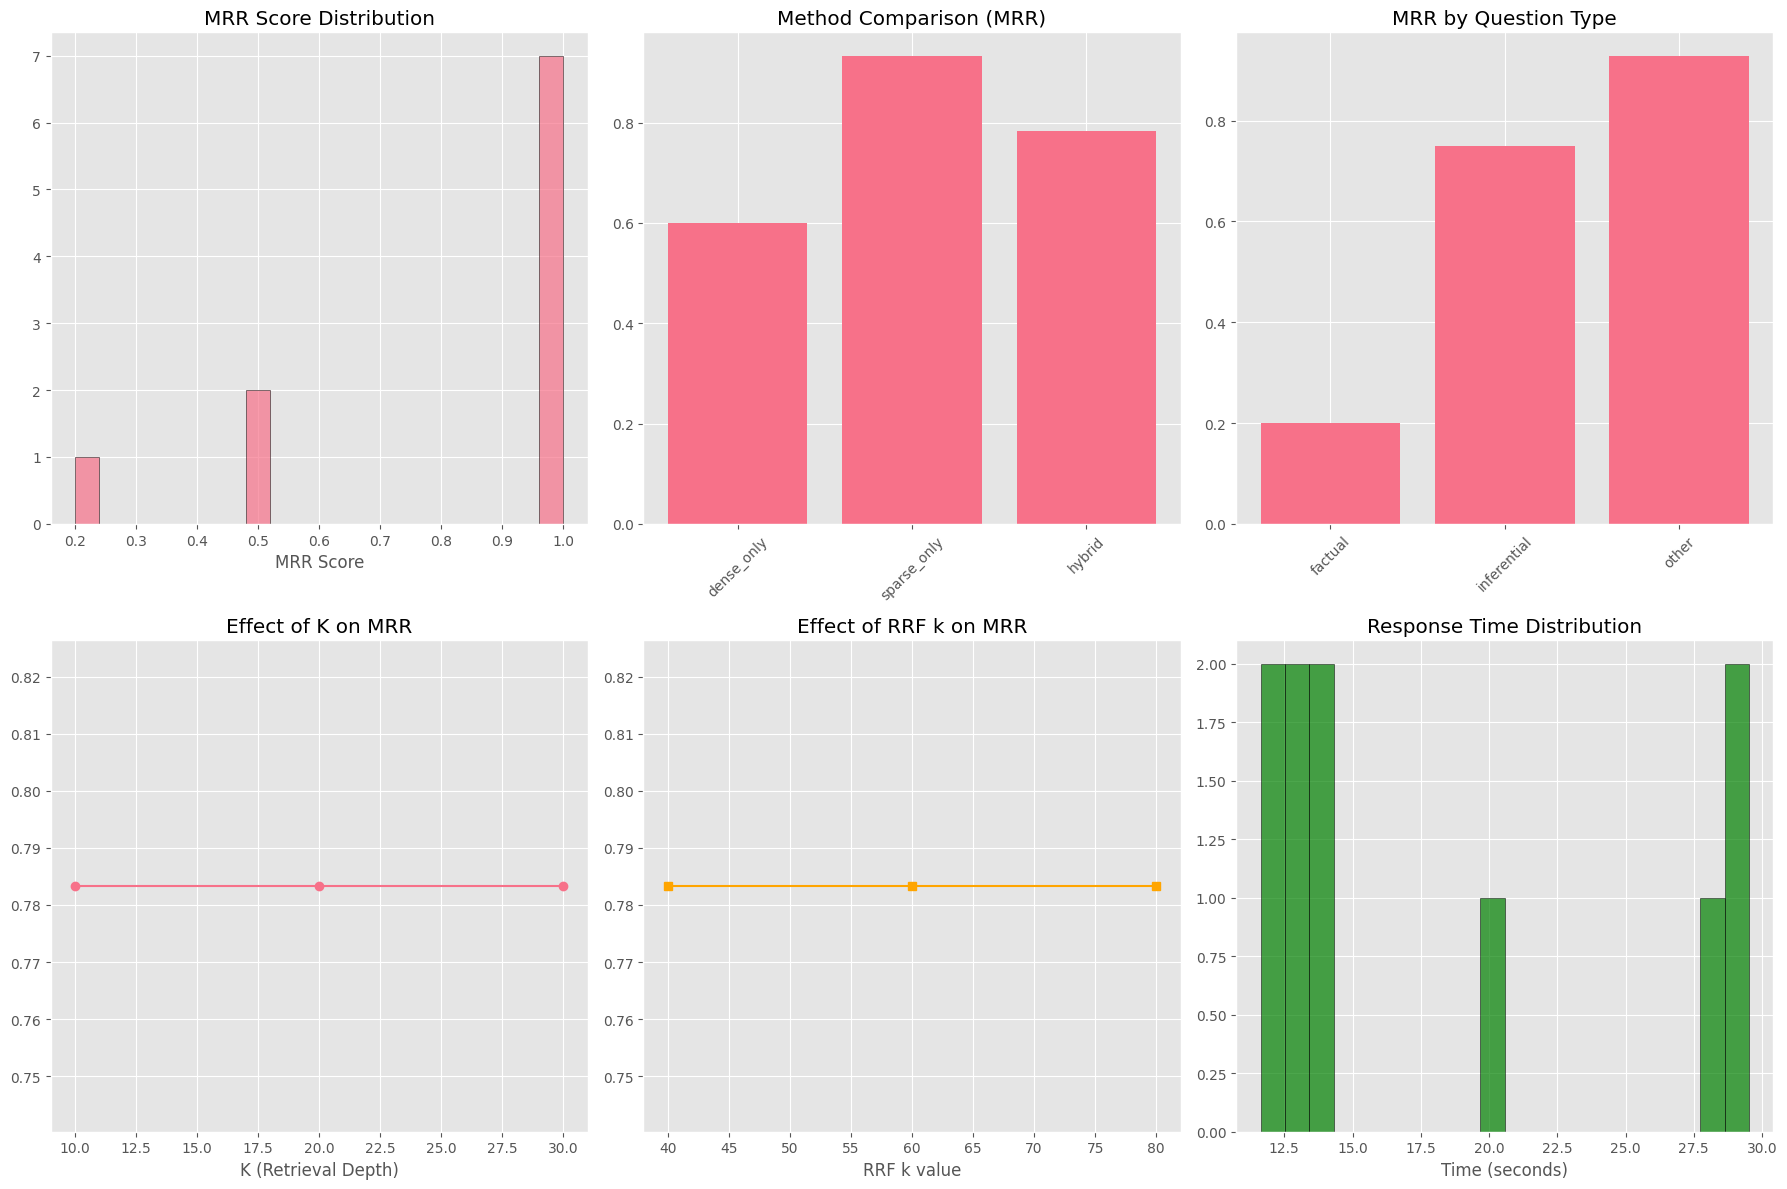

Generating error analysis visualizations...


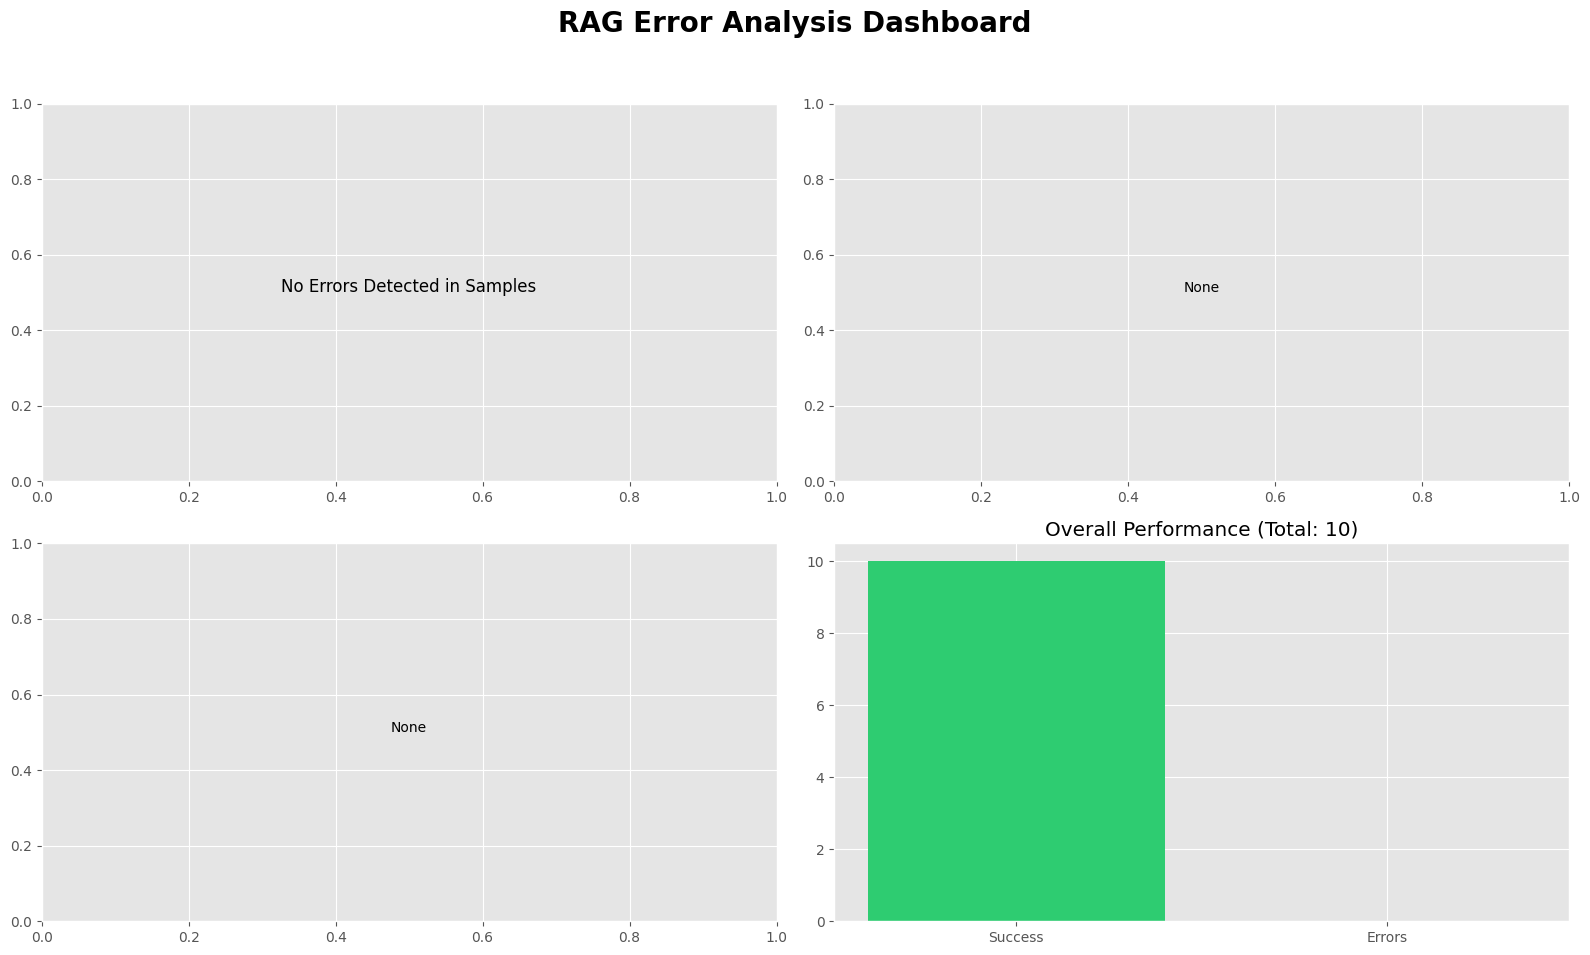

✅ Dashboard saved to full_evaluation_results/error_analysis_dashboard.png
✅ Detailed JSON results saved to full_evaluation_results/error_analysis_results.json

EVALUATION COMPLETE
Results saved to: full_evaluation_results


In [44]:
# Initialize and run verification evaluation and store results
pipeline = AutomatedEvaluationPipeline(rag_system, evaluator, error_analyzer)
final_results, final_per_question_results = pipeline.run_full_evaluation(qa_pairs, num_qa_pairs=10)

----END----